In [72]:

# Lab Exercise 9 - SVM Binary Classification



import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

# Dataset generation
from sklearn.datasets import make_classification

# Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# SVM
from sklearn.svm import SVC

# Evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Ignore unnecessary warnings
import warnings
warnings.filterwarnings("ignore")

print(" All libraries imported successfully!")

 All libraries imported successfully!


In [73]:

#  Create Synthetic Hospital Patient Dataset


X, y = make_classification(
    n_samples=1000,
    n_features=7,
    n_informative=5,
    n_redundant=1,
    n_repeated=0,
    n_classes=2,
    n_clusters_per_class=2,
    class_sep=1.2,
    flip_y=0.05,
    weights=[0.50, 0.50],
    random_state=42
)

# Meaningful feature names
feature_names = [
    "age",
    "bmi",
    "heart_rate",
    "glucose",
    "blood_pressure",
    "respiration_rate",
    "severity_score"
]

# Create DataFrame
df = pd.DataFrame(X, columns=feature_names)

# Add binary target
df["high_risk"] = y

# Display first 10 records
print("First 10 Records:")
display(df.head(10))

# Display shape
print("\nDataset Shape:")
print(df.shape)

First 10 Records:


,age,bmi,heart_rate,glucose,blood_pressure,respiration_rate,severity_score,high_risk
0,-0.574083,-1.249251,1.200104,0.852324,-1.809790,-2.304518,-0.142766,0
1,-1.547802,-1.077559,-1.073578,-2.954809,-0.741240,-2.521960,1.462148,1
2,0.716589,0.685211,0.929165,2.442694,-2.009040,-2.011523,-1.767841,0
3,0.337956,3.432119,-1.852753,0.872259,0.813594,0.046883,-4.208159,1
4,1.636740,-1.541791,2.630308,1.970351,0.141282,0.040710,-0.611210,1
5,-0.972765,-1.691382,2.229284,4.394856,-1.234377,3.155307,0.085907,1
6,-0.147340,0.595707,-0.032173,0.432640,0.565162,-1.737483,-3.933403,1
7,0.034375,1.909535,0.469832,4.119703,-3.026211,-1.554116,-2.725239,0
8,0.223281,0.574244,1.343290,-1.010304,0.679851,-2.256357,0.904504,0
9,-0.220538,1.683269,2.026025,-0.393815,1.078860,-1.223234,2.408718,0



Dataset Shape:
(1000, 8)


In [74]:

#Dataset Information


print("Dataset Shape:")
print(df.shape)

print("\nData Types:")
print(df.dtypes)

print("\nDataset Information:")
df.info()

print("\nDescriptive Statistics:")
display(df.describe())

print("\nClass Distribution:")
print(df["high_risk"].value_counts())

Dataset Shape:
(1000, 8)

Data Types:
age                 float64
bmi                 float64
heart_rate          float64
glucose             float64
blood_pressure      float64
respiration_rate    float64
severity_score      float64
high_risk             int64
dtype: object

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   age               1000 non-null   float64
 1   bmi               1000 non-null   float64
 2   heart_rate        1000 non-null   float64
 3   glucose           1000 non-null   float64
 4   blood_pressure    1000 non-null   float64
 5   respiration_rate  1000 non-null   float64
 6   severity_score    1000 non-null   float64
 7   high_risk         1000 non-null   int64  
dtypes: float64(7), int64(1)
memory usage: 62.6 KB

Descriptive Statistics:


,age,bmi,heart_rate,glucose,blood_pressure,respiration_rate,severity_score,high_risk
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.00000
mean,-0.038916,0.569059,0.599845,-0.129934,0.580472,-0.592447,-0.011035,0.51000
std,1.007514,1.601325,1.722766,2.527313,1.688125,1.631213,1.748538,0.50015
min,-2.899514,-3.689284,-4.141477,-7.678079,-4.861168,-4.458034,-6.014203,0.00000
25%,-0.684881,-0.645880,-0.701585,-1.903681,-0.520833,-1.694526,-1.293807,0.00000
50%,-0.038242,0.725408,0.626671,-0.372049,0.750886,-0.940346,0.064898,1.00000
75%,0.623924,1.647875,1.731734,1.666714,1.716947,0.121632,1.257479,1.00000
max,3.098299,6.236793,5.808412,6.426613,5.266061,5.885693,4.805669,1.00000



Class Distribution:
high_risk
1    510
0    490
Name: count, dtype: int64


In [75]:

# Save Dataset

df.to_csv("Hospital_SVM_Binary_Classification.csv", index=False)

print(" Dataset saved successfully!")

# Verify the file
import os

print("\nFiles in current directory:")
print(os.listdir())

 Dataset saved successfully!

Files in current directory:
['.config', 'Hospital_SVM_Binary_Classification.csv', 'sample_data']


In [76]:

# Check Missing Values and Duplicates


print("Missing Values:")
display(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

print("\nNumber of Duplicate Records:")
print(df.duplicated().sum())

Missing Values:


,0
age,0
bmi,0
heart_rate,0
glucose,0
blood_pressure,0
respiration_rate,0
severity_score,0
high_risk,0



Total Missing Values:
0

Number of Duplicate Records:
0


In [77]:

#  Data Preprocessing


# Remove duplicate records
df = df.drop_duplicates()

# Separate independent variables and target
X = df.drop("high_risk", axis=1)
y = df["high_risk"]

print("Independent Variables (X):")
display(X.head())

print("\nTarget Variable (y):")
display(y.head())

print("\nX Shape:", X.shape)
print("y Shape:", y.shape)

Independent Variables (X):


,age,bmi,heart_rate,glucose,blood_pressure,respiration_rate,severity_score
0,-0.574083,-1.249251,1.200104,0.852324,-1.809790,-2.304518,-0.142766
1,-1.547802,-1.077559,-1.073578,-2.954809,-0.741240,-2.521960,1.462148
2,0.716589,0.685211,0.929165,2.442694,-2.009040,-2.011523,-1.767841
3,0.337956,3.432119,-1.852753,0.872259,0.813594,0.046883,-4.208159
4,1.636740,-1.541791,2.630308,1.970351,0.141282,0.040710,-0.611210



Target Variable (y):


,high_risk
0,0
1,1
2,0
3,1
4,1



X Shape: (1000, 7)
y Shape: (1000,)


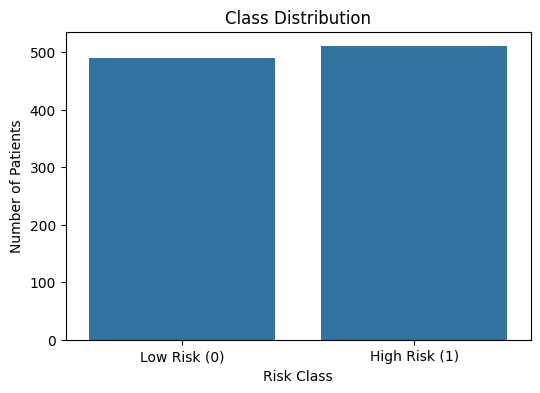

In [78]:

#  Class Distribution


plt.figure(figsize=(6, 4))

sns.countplot(
    x=df["high_risk"]
)

plt.title("Class Distribution")
plt.xlabel("Risk Class")
plt.ylabel("Number of Patients")

plt.xticks(
    [0, 1],
    ["Low Risk (0)", "High Risk (1)"]
)

plt.show()

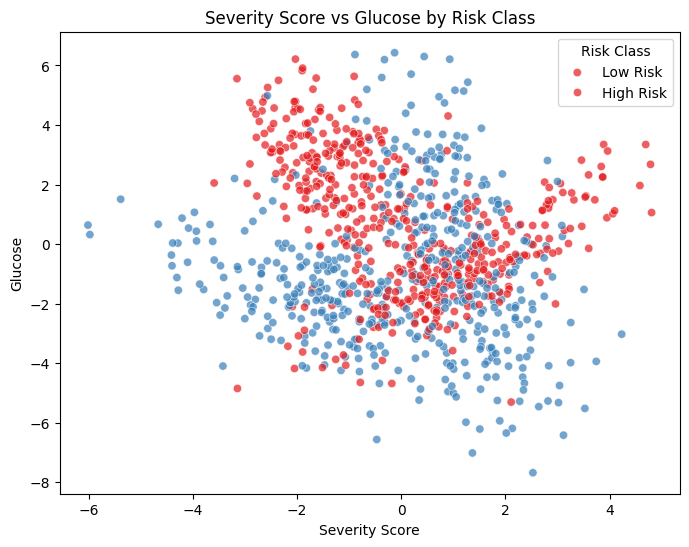

In [79]:

#  Scatter Plot


plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x="severity_score",
    y="glucose",
    hue="high_risk",
    palette="Set1",
    alpha=0.7
)

plt.title("Severity Score vs Glucose by Risk Class")
plt.xlabel("Severity Score")
plt.ylabel("Glucose")
plt.legend(
    title="Risk Class",
    labels=["Low Risk", "High Risk"]
)

plt.show()


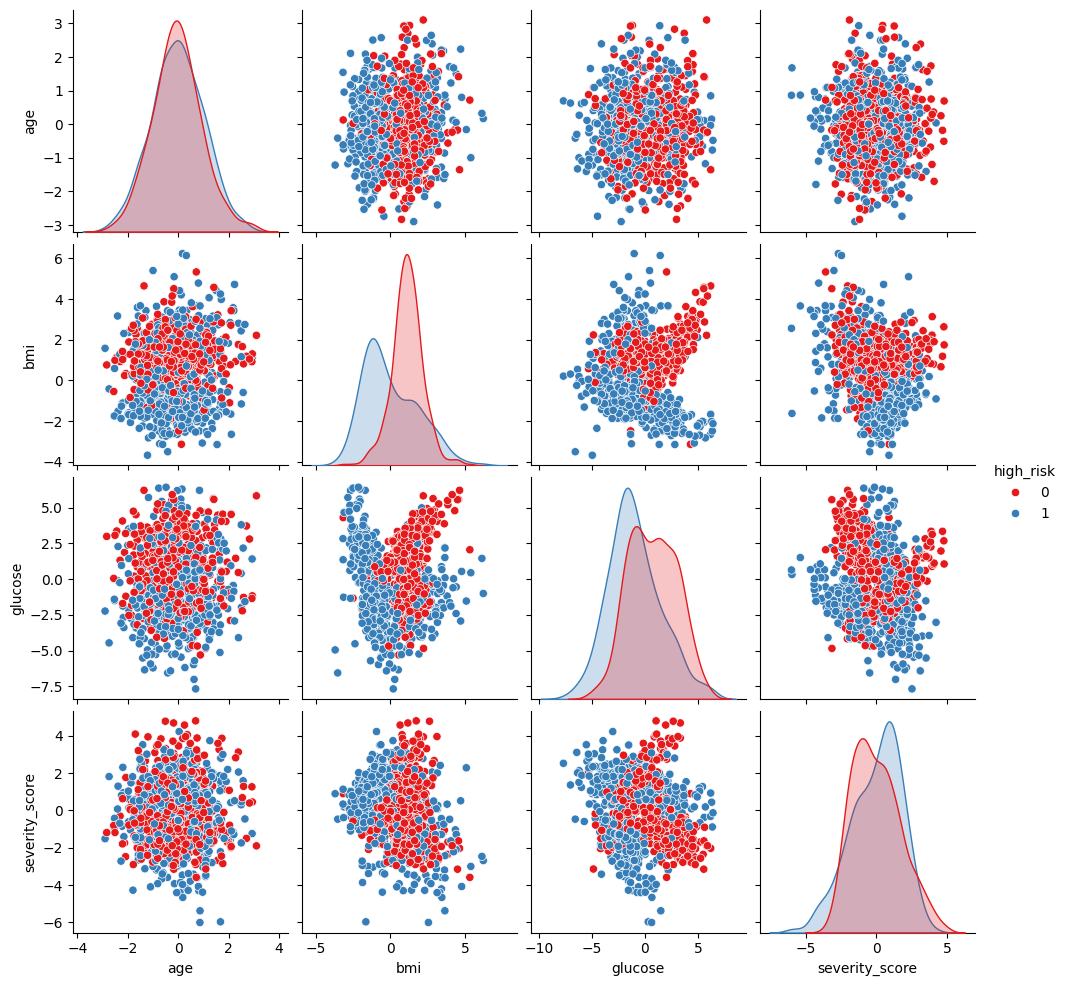

In [80]:

# Pair Plot


selected_features = [
    "age",
    "bmi",
    "glucose",
    "severity_score",
    "high_risk"
]

sns.pairplot(
    df[selected_features],
    hue="high_risk",
    palette="Set1"
)

plt.show()

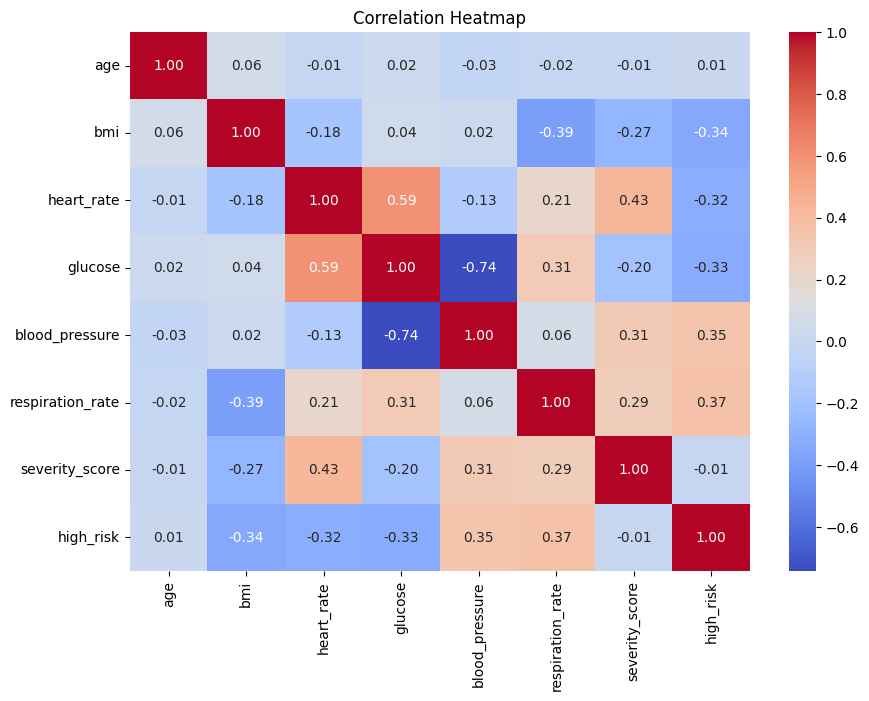

In [81]:

#  Correlation Heatmap

plt.figure(figsize=(10, 7))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [82]:

#  Train-Test Split


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Samples:", X_train.shape[0])
print("Testing Samples :", X_test.shape[0])

print("\nTraining Class Distribution:")
print(y_train.value_counts())

print("\nTesting Class Distribution:")
print(y_test.value_counts())

Training Samples: 800
Testing Samples : 200

Training Class Distribution:
high_risk
1    408
0    392
Name: count, dtype: int64

Testing Class Distribution:
high_risk
1    102
0     98
Name: count, dtype: int64


In [83]:

#  Feature Scaling


scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")

print("\nFirst 5 scaled training records:")
display(pd.DataFrame(
    X_train_scaled,
    columns=feature_names
).head())

Feature scaling completed successfully!

First 5 scaled training records:


,age,bmi,heart_rate,glucose,blood_pressure,respiration_rate,severity_score
0,0.215738,-1.494209,-0.141764,0.097555,0.092491,1.767263,0.356123
1,-1.152761,0.091704,-0.185543,0.987211,-1.739881,-0.990420,-1.354543
2,-0.666084,-1.367065,0.860383,0.433195,-0.295751,0.442590,0.376425
3,-1.676247,-1.262864,1.016175,1.293241,-0.511721,1.540031,-0.162990
4,1.661221,0.824672,-1.446954,-1.412338,0.838946,-0.789472,-0.280659


In [84]:

# Linear SVM

linear_svm = SVC(
    kernel="linear",
    C=1.0
)

linear_svm.fit(
    X_train_scaled,
    y_train
)

print("Linear SVM trained successfully!")

# Predictions
y_pred_linear = linear_svm.predict(X_test_scaled)

print("Predictions generated successfully!")

Linear SVM trained successfully!
Predictions generated successfully!


In [85]:

# Linear SVM Evaluation


accuracy_linear = accuracy_score(y_test, y_pred_linear)

precision_linear = precision_score(
    y_test,
    y_pred_linear
)

recall_linear = recall_score(
    y_test,
    y_pred_linear
)

f1_linear = f1_score(
    y_test,
    y_pred_linear
)

print("Linear SVM Performance")
print("----------------------")

print("Accuracy :", round(accuracy_linear, 4))
print("Precision:", round(precision_linear, 4))
print("Recall   :", round(recall_linear, 4))
print("F1 Score :", round(f1_linear, 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_linear))

Linear SVM Performance
----------------------
Accuracy : 0.82
Precision: 0.7845
Recall   : 0.8922
F1 Score : 0.8349

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.74      0.80        98
           1       0.78      0.89      0.83       102

    accuracy                           0.82       200
   macro avg       0.83      0.82      0.82       200
weighted avg       0.83      0.82      0.82       200



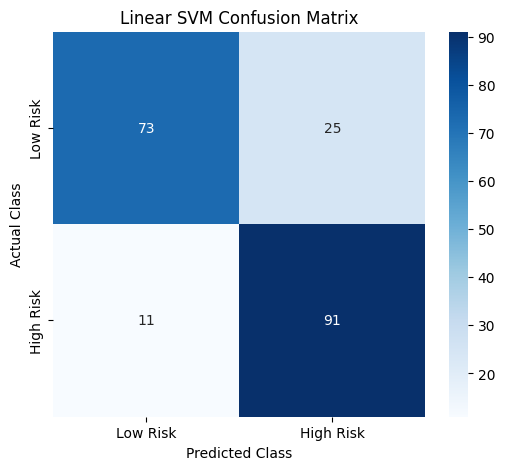

In [86]:

#  Confusion Matrix


cm_linear = confusion_matrix(
    y_test,
    y_pred_linear
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm_linear,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Low Risk", "High Risk"],
    yticklabels=["Low Risk", "High Risk"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Linear SVM Confusion Matrix")

plt.show()

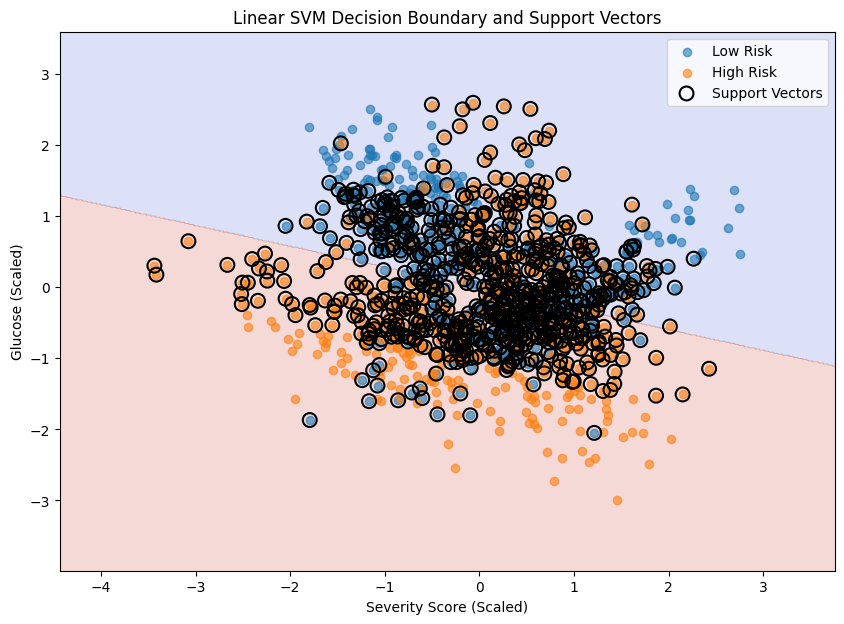

Number of Support Vectors: 769


In [87]:

#  SVM Decision Boundary and Support Vectors


# Select two features for visualization
visual_features = ["severity_score", "glucose"]

X_visual = df[visual_features]
y_visual = df["high_risk"]

# Scale the two features
visual_scaler = StandardScaler()

X_visual_scaled = visual_scaler.fit_transform(X_visual)

# Train a separate 2D Linear SVM
svm_2d = SVC(
    kernel="linear",
    C=1.0
)

svm_2d.fit(
    X_visual_scaled,
    y_visual
)

# Create grid
x_min = X_visual_scaled[:, 0].min() - 1
x_max = X_visual_scaled[:, 0].max() + 1

y_min = X_visual_scaled[:, 1].min() - 1
y_max = X_visual_scaled[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 500),
    np.linspace(y_min, y_max, 500)
)

grid = np.c_[xx.ravel(), yy.ravel()]

Z = svm_2d.predict(grid)

Z = Z.reshape(xx.shape)

# Plot decision regions
plt.figure(figsize=(10, 7))

plt.contourf(
    xx,
    yy,
    Z,
    alpha=0.2,
    cmap="coolwarm"
)

# Plot observations
plt.scatter(
    X_visual_scaled[y_visual == 0, 0],
    X_visual_scaled[y_visual == 0, 1],
    label="Low Risk",
    alpha=0.6
)

plt.scatter(
    X_visual_scaled[y_visual == 1, 0],
    X_visual_scaled[y_visual == 1, 1],
    label="High Risk",
    alpha=0.6
)

# Highlight support vectors
plt.scatter(
    svm_2d.support_vectors_[:, 0],
    svm_2d.support_vectors_[:, 1],
    s=100,
    facecolors="none",
    edgecolors="black",
    linewidths=1.5,
    label="Support Vectors"
)

plt.xlabel("Severity Score (Scaled)")
plt.ylabel("Glucose (Scaled)")
plt.title("Linear SVM Decision Boundary and Support Vectors")

plt.legend()
plt.show()

print("Number of Support Vectors:",
      len(svm_2d.support_vectors_))

In [88]:

#  Effect of C


C_values = [0.01, 1, 100]

results = []

for c_value in C_values:

    svm_model = SVC(
        kernel="linear",
        C=c_value
    )

    svm_model.fit(
        X_train_scaled,
        y_train
    )

    predictions = svm_model.predict(
        X_test_scaled
    )

    results.append({
        "C": c_value,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions)
    })

results_df = pd.DataFrame(results)

display(results_df)

,C,Accuracy,Precision,Recall,F1 Score
0,0.01,0.835,0.780488,0.941176,0.853333
1,1.00,0.820,0.784483,0.892157,0.834862
2,100.00,0.820,0.784483,0.892157,0.834862


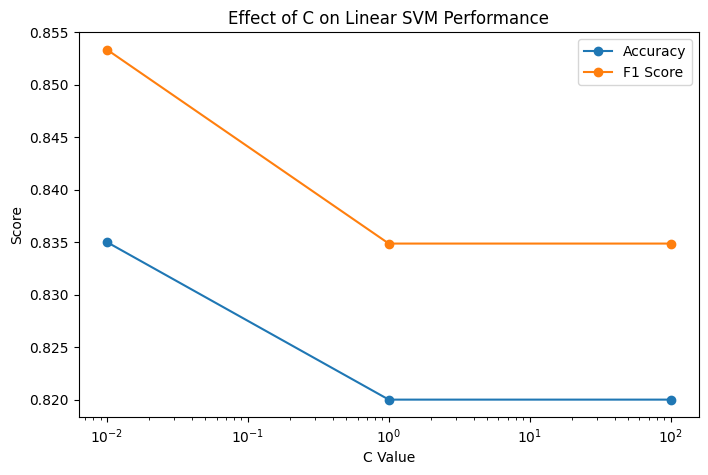

In [89]:

#  C Value Performance Comparison

plt.figure(figsize=(8, 5))

plt.plot(
    results_df["C"],
    results_df["Accuracy"],
    marker="o",
    label="Accuracy"
)

plt.plot(
    results_df["C"],
    results_df["F1 Score"],
    marker="o",
    label="F1 Score"
)

plt.xscale("log")

plt.xlabel("C Value")
plt.ylabel("Score")

plt.title("Effect of C on Linear SVM Performance")

plt.legend()

plt.show()

In [90]:

# Select Best C


best_row = results_df.loc[
    results_df["F1 Score"].idxmax()
]

best_C = best_row["C"]

print("Best C Value:", best_C)

print("\nBest Model Performance:")
display(best_row)

Best C Value: 0.01

Best Model Performance:


,0
C,0.010000
Accuracy,0.835000
Precision,0.780488
Recall,0.941176
F1 Score,0.853333


In [91]:

# Final SVM Model

final_svm = SVC(
    kernel="linear",
    C=best_C
)

final_svm.fit(
    X_train_scaled,
    y_train
)

final_predictions = final_svm.predict(
    X_test_scaled
)

print("Final SVM model trained successfully!")

Final SVM model trained successfully!


In [92]:

#Final Model Evaluation


final_accuracy = accuracy_score(
    y_test,
    final_predictions
)

final_precision = precision_score(
    y_test,
    final_predictions
)

final_recall = recall_score(
    y_test,
    final_predictions
)

final_f1 = f1_score(
    y_test,
    final_predictions
)

print("FINAL SVM PERFORMANCE")
print("=====================")

print("Accuracy :", round(final_accuracy, 4))
print("Precision:", round(final_precision, 4))
print("Recall   :", round(final_recall, 4))
print("F1 Score :", round(final_f1, 4))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        final_predictions,
        target_names=["Low Risk", "High Risk"]
    )
)

FINAL SVM PERFORMANCE
Accuracy : 0.835
Precision: 0.7805
Recall   : 0.9412
F1 Score : 0.8533

Classification Report:
              precision    recall  f1-score   support

    Low Risk       0.92      0.72      0.81        98
   High Risk       0.78      0.94      0.85       102

    accuracy                           0.83       200
   macro avg       0.85      0.83      0.83       200
weighted avg       0.85      0.83      0.83       200



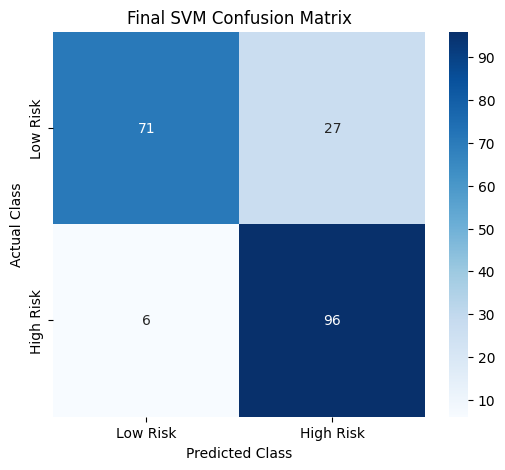

In [93]:

# Final Confusion Matrix

final_cm = confusion_matrix(
    y_test,
    final_predictions
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    final_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Low Risk", "High Risk"],
    yticklabels=["Low Risk", "High Risk"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.title("Final SVM Confusion Matrix")

plt.show()

In [94]:

# Block 23 : Support Vector Analysis


print("Number of Support Vectors:")
print(final_svm.n_support_)

print("\nTotal Support Vectors:")
print(final_svm.n_support_.sum())

Number of Support Vectors:
[235 236]

Total Support Vectors:
471
